# Análisis Exploratorio de Datos (EDA) · Café Gourmet ☕

**Objetivo:** entender el conjunto de datos `data/datos.csv` antes de construir el dashboard en Streamlit (`app.py`).

En este notebook se revisa:

1. Estructura general del dataset
2. Tipos de datos de cada columna
3. Valores faltantes y registros duplicados
4. Consistencia de los datos
5. Estadísticas descriptivas
6. Distribuciones y visualizaciones
7. Relaciones entre variables
8. Hallazgos y decisiones para la aplicación

## 0. Librerías y carga de datos

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", None)

# utf-8-sig elimina el carácter BOM que trae el encabezado del CSV
df = pd.read_csv("data/datos.csv", encoding="utf-8-sig")

## 1. Estructura general del dataset

In [2]:
print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")
df.head()

Filas: 150 | Columnas: 17


,id_venta,fecha_venta,dia_semana,sucursal,id_cliente,producto,categoria,precio_unitario,cantidad,ventas_totales,costo_total,metodo_pago,satisfaccion,tiempo_preparacion_min,es_cliente_frecuente,es_pedido_para_llevar,tiene_descuento
0,V0001,2026-03-23,lunes,Roma Norte,C072,Americano,Café,49.40,2,83.98,36.0,Tarjeta,4,4,True,True,True
1,V0002,2026-01-26,lunes,Roma Norte,C044,Panqué de limón,Panadería,42.75,2,85.50,34.0,Transferencia,5,3,False,True,False
2,V0003,2026-02-05,jueves,Polanco,C011,Cappuccino,Café,68.00,3,183.60,72.0,Transferencia,5,5,True,True,True
3,V0004,2026-03-12,jueves,Roma Norte,C011,Latte vainilla,Café,72.20,2,144.40,54.0,Billetera digital,2,4,False,True,False
4,V0005,2026-01-30,viernes,Condesa,C069,Brownie de chocolate,Postres,55.00,1,55.00,22.0,Efectivo,3,4,False,False,False


In [3]:
df.columns.tolist()

['id_venta', 'fecha_venta', 'dia_semana', 'sucursal', 'id_cliente', 'producto', 'categoria', 'precio_unitario', 'cantidad', 'ventas_totales', 'costo_total', 'metodo_pago', 'satisfaccion', 'tiempo_preparacion_min', 'es_cliente_frecuente', 'es_pedido_para_llevar', 'tiene_descuento']

Cada fila es **una venta** (`id_venta`) con información de:

- **Cuándo:** `fecha_venta`, `dia_semana`
- **Dónde y quién:** `sucursal`, `id_cliente`
- **Qué:** `producto`, `categoria`, `precio_unitario`, `cantidad`
- **Cuánto:** `ventas_totales`, `costo_total`
- **Cómo:** `metodo_pago`, `es_pedido_para_llevar`, `tiene_descuento`
- **Experiencia:** `satisfaccion` (1–5), `tiempo_preparacion_min`, `es_cliente_frecuente`

## 2. Tipos de datos

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id_venta                150 non-null    str    
 1   fecha_venta             150 non-null    str    
 2   dia_semana              150 non-null    str    
 3   sucursal                150 non-null    str    
 4   id_cliente              150 non-null    str    
 5   producto                150 non-null    str    
 6   categoria               150 non-null    str    
 7   precio_unitario         150 non-null    float64
 8   cantidad                150 non-null    int64  
 9   ventas_totales          150 non-null    float64
 10  costo_total             150 non-null    float64
 11  metodo_pago             150 non-null    str    
 12  satisfaccion            150 non-null    int64  
 13  tiempo_preparacion_min  150 non-null    int64  
 14  es_cliente_frecuente    150 non-null    bool   
 15  

`fecha_venta` se lee como texto, así que se convierte a fecha para poder filtrar por periodo (igual que en `app.py`).

In [5]:
df["fecha_venta"] = pd.to_datetime(df["fecha_venta"], errors="coerce")
print("Fechas no convertibles:", df["fecha_venta"].isna().sum())
print("Periodo:", df["fecha_venta"].min().date(), "a", df["fecha_venta"].max().date())
df.dtypes

Fechas no convertibles: 0
Periodo: 2026-01-01 a 2026-03-29


id_venta                             str
fecha_venta               datetime64[us]
dia_semana                           str
sucursal                             str
id_cliente                           str
producto                             str
categoria                            str
precio_unitario                  float64
cantidad                           int64
ventas_totales                   float64
costo_total                      float64
metodo_pago                          str
satisfaccion                       int64
tiempo_preparacion_min             int64
es_cliente_frecuente                bool
es_pedido_para_llevar               bool
tiene_descuento                     bool
dtype: object

## 3. Valores faltantes y duplicados

In [6]:
faltantes = df.isna().sum().to_frame("faltantes")
faltantes["%"] = (faltantes["faltantes"] / len(df) * 100).round(2)
faltantes

,faltantes,%
id_venta,0,0.0
fecha_venta,0,0.0
dia_semana,0,0.0
sucursal,0,0.0
id_cliente,0,0.0
producto,0,0.0
categoria,0,0.0
precio_unitario,0,0.0
cantidad,0,0.0
ventas_totales,0,0.0


In [7]:
print("Filas duplicadas completas:", df.duplicated().sum())
print("id_venta repetidos:", df["id_venta"].duplicated().sum())

Filas duplicadas completas: 0
id_venta repetidos: 0


No hay valores faltantes ni registros duplicados, por lo que **no se requiere imputación ni eliminación de filas**.

## 4. Consistencia de los datos

Se verifica que `ventas_totales = precio_unitario × cantidad` y se revisa si las diferencias corresponden a descuentos.

In [8]:
df["importe_bruto"] = (df["precio_unitario"] * df["cantidad"]).round(2)
df["diferencia"] = (df["importe_bruto"] - df["ventas_totales"]).round(2)

df.groupby("tiene_descuento").agg(
    ventas=("id_venta", "count"),
    ventas_con_diferencia=("diferencia", lambda s: (s > 0).sum()),
)

,ventas,ventas_con_diferencia
tiene_descuento,,
False,130,0
True,20,20


In [9]:
pct_pagado = (df["ventas_totales"] / df["importe_bruto"]).groupby(df["tiene_descuento"]).mean()
print("Proporción pagada del importe bruto:")
print(pct_pagado.round(3))

Proporción pagada del importe bruto:
tiene_descuento
False    1.00
True     0.91
dtype: float64


In [10]:
# ¿El precio de un mismo producto cambia según la sucursal?
df.pivot_table(index="producto", columns="sucursal", values="precio_unitario", aggfunc="mean").round(2)

sucursal,Condesa,Polanco,Roma Norte
producto,,,
Americano,51.48,52.00,51.13
Brownie de chocolate,55.92,56.38,53.17
Cappuccino,68.85,67.15,67.43
Cheesecake frutos rojos,78.00,74.10,78.78
Cold brew,73.47,77.70,74.82
Croissant de mantequilla,49.00,49.00,50.22
Espresso doble,47.04,48.96,48.00
Flat white,70.80,75.60,72.00
Frappé moka,91.22,89.00,90.48


In [11]:
# Validaciones de rango
print("Satisfacción fuera de 1-5:", (~df["satisfaccion"].between(1, 5)).sum())
print("Cantidades <= 0:", (df["cantidad"] <= 0).sum())
print("Ventas con costo mayor al importe:", (df["costo_total"] > df["ventas_totales"]).sum())

Satisfacción fuera de 1-5: 0
Cantidades <= 0: 0
Ventas con costo mayor al importe: 0


## 5. Estadísticas descriptivas

In [12]:
numericas = ["precio_unitario", "cantidad", "ventas_totales", "costo_total",
             "satisfaccion", "tiempo_preparacion_min"]
df[numericas].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
precio_unitario,150.0,69.13,22.27,42.75,50.40,69.2,77.70,134.40
cantidad,150.0,1.69,0.86,1.00,1.00,1.0,2.00,4.00
ventas_totales,150.0,113.18,63.75,38.25,68.50,90.0,146.35,327.75
costo_total,150.0,43.88,27.66,17.00,24.25,34.0,54.00,162.00
satisfaccion,150.0,4.08,0.94,2.00,3.00,4.0,5.00,5.00
tiempo_preparacion_min,150.0,4.85,2.34,2.00,3.00,4.5,6.75,11.00


In [13]:
df.describe(include=['object', 'string', 'bool']).T

,count,unique,top,freq
id_venta,150,150,V0001,1
dia_semana,150,7,domingo,27
sucursal,150,3,Roma Norte,67
id_cliente,150,69,C011,5
producto,150,15,Panqué de limón,17
categoria,150,6,Café,52
metodo_pago,150,4,Transferencia,46
es_cliente_frecuente,150,2,False,92
es_pedido_para_llevar,150,2,True,86
tiene_descuento,150,2,False,130


In [14]:
# Indicadores generales del negocio
total = df["ventas_totales"].sum()
margen = (df["ventas_totales"] - df["costo_total"]).sum() / total
print(f"Ventas totales: ${total:,.2f} MXN")
print(f"Ticket promedio: ${df['ventas_totales'].mean():,.2f} MXN (mediana ${df['ventas_totales'].median():,.2f})")
print(f"Margen bruto: {margen:.1%}")
print(f"Clientes únicos: {df['id_cliente'].nunique()}")
print(f"Clientes frecuentes: {df['es_cliente_frecuente'].mean():.1%} de las ventas")
print(f"Pedidos para llevar: {df['es_pedido_para_llevar'].mean():.1%}")
print(f"Ventas con descuento: {df['tiene_descuento'].mean():.1%}")

Ventas totales: $16,976.60 MXN
Ticket promedio: $113.18 MXN (mediana $90.00)
Margen bruto: 61.2%
Clientes únicos: 69
Clientes frecuentes: 38.7% de las ventas
Pedidos para llevar: 57.3%
Ventas con descuento: 13.3%


## 6. Distribuciones

### 6.1 Importe por venta (`ventas_totales`)

Límite superior (IQR): $263.12 -> 7 ventas atípicas


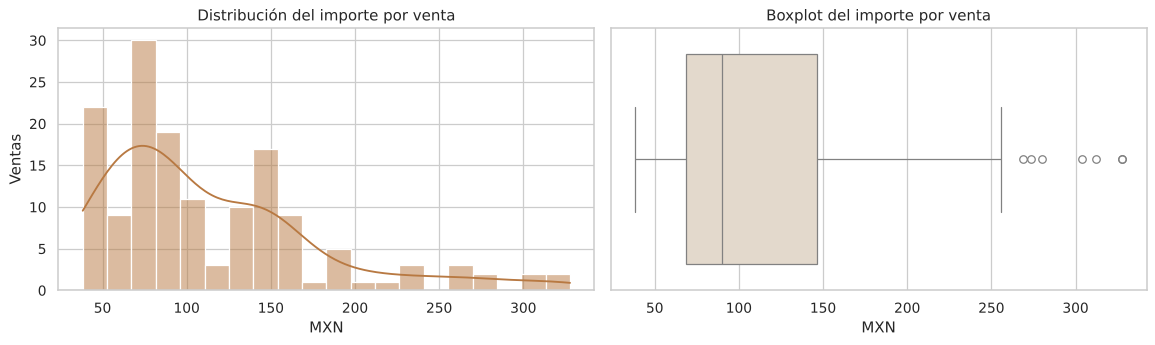

,id_venta,producto,cantidad,precio_unitario,ventas_totales
12,V0013,Cheesecake frutos rojos,4,78.00,312.00
19,V0020,Flat white,4,68.40,273.60
22,V0023,Sándwich artesanal,3,109.25,327.75
41,V0042,Frappé moka,3,93.45,280.35
55,V0056,Toast de aguacate,2,134.40,268.80
81,V0082,Sándwich artesanal,3,109.25,327.75
129,V0130,Latte vainilla,4,76.00,304.00


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["ventas_totales"], bins=20, kde=True, ax=axes[0], color="#B87942")
axes[0].set(title="Distribución del importe por venta", xlabel="MXN", ylabel="Ventas")
sns.boxplot(x=df["ventas_totales"], ax=axes[1], color="#E7D9C8")
axes[1].set(title="Boxplot del importe por venta", xlabel="MXN")
plt.tight_layout()
plt.show()

q1, q3 = df["ventas_totales"].quantile([0.25, 0.75])
limite = q3 + 1.5 * (q3 - q1)
atipicos = df[df["ventas_totales"] > limite]
print(f"Límite superior (IQR): ${limite:,.2f} -> {len(atipicos)} ventas atípicas")
atipicos[["id_venta", "producto", "cantidad", "precio_unitario", "ventas_totales"]]

La distribución tiene **sesgo a la derecha**: la mayoría de las ventas son de 1–2 unidades y unas pocas compras de 3–4 unidades elevan el promedio. Los valores atípicos son compras grandes legítimas, no errores, así que **se conservan**.

### 6.2 Variables numéricas

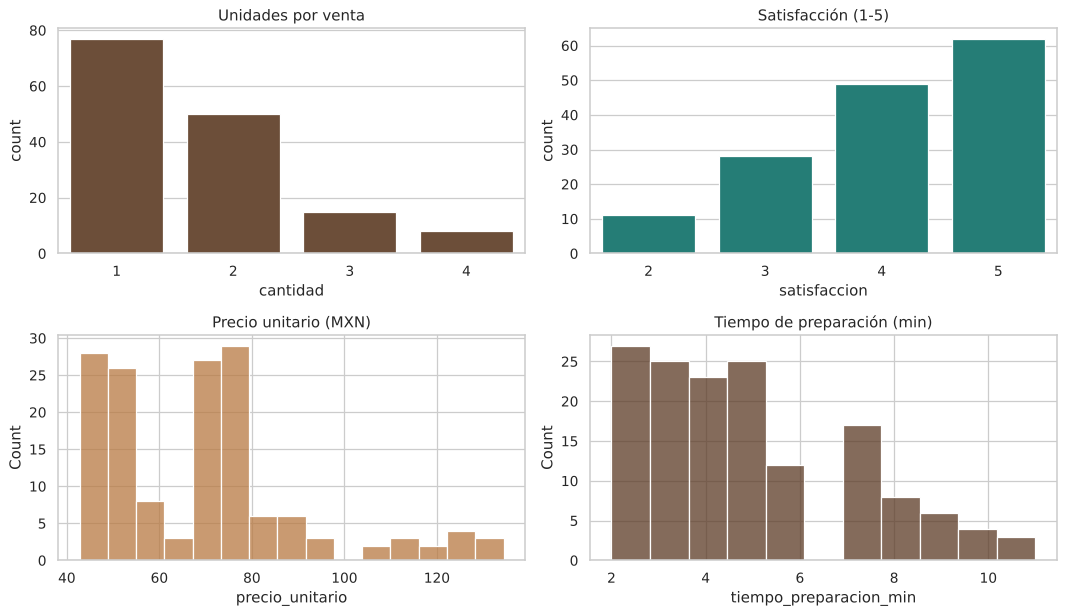

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
sns.countplot(x="cantidad", data=df, ax=axes[0, 0], color="#754C30")
axes[0, 0].set_title("Unidades por venta")
sns.countplot(x="satisfaccion", data=df, ax=axes[0, 1], color="#168C82")
axes[0, 1].set_title("Satisfacción (1-5)")
sns.histplot(df["precio_unitario"], bins=15, ax=axes[1, 0], color="#B87942")
axes[1, 0].set_title("Precio unitario (MXN)")
sns.histplot(df["tiempo_preparacion_min"], bins=11, ax=axes[1, 1], color="#5B3924")
axes[1, 1].set_title("Tiempo de preparación (min)")
plt.tight_layout()
plt.show()

### 6.3 Variables categóricas

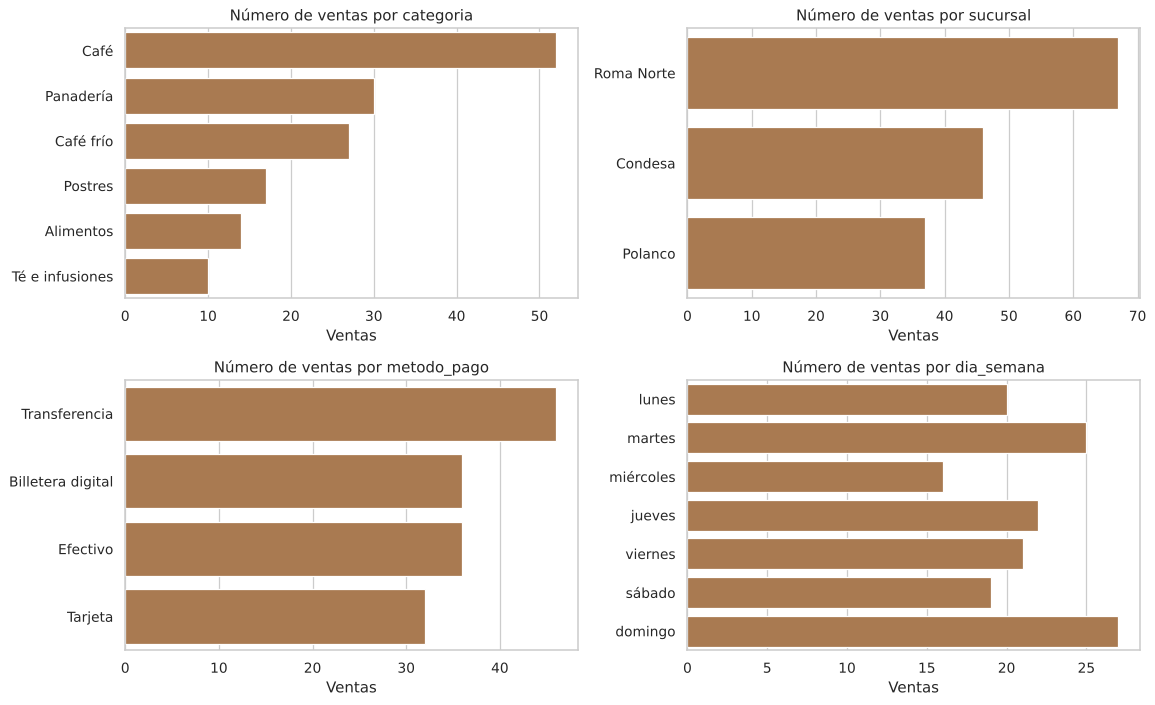

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.flat, ["categoria", "sucursal", "metodo_pago", "dia_semana"]):
    orden = df[col].value_counts().index
    if col == "dia_semana":
        orden = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
    sns.countplot(y=col, data=df, order=orden, ax=ax, color="#B87942")
    ax.set(title=f"Número de ventas por {col}", xlabel="Ventas", ylabel="")
plt.tight_layout()
plt.show()

## 7. Ventas por producto, categoría y sucursal

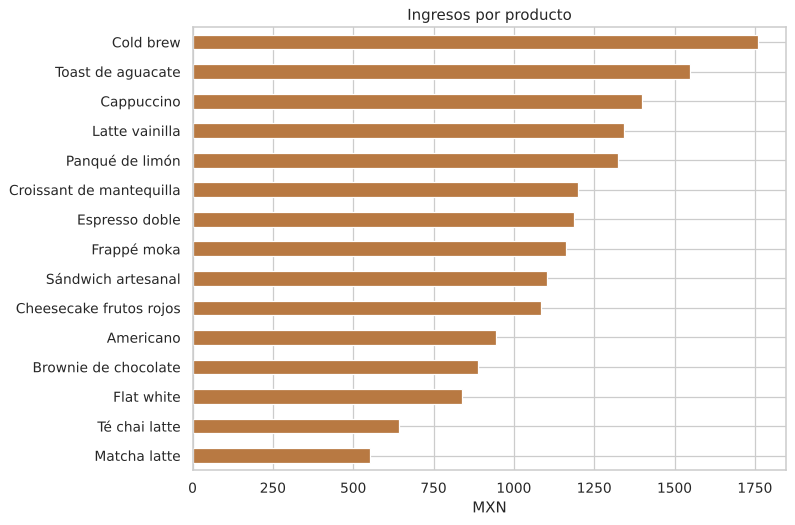

In [18]:
ventas_producto = df.groupby("producto")["ventas_totales"].sum().sort_values()
ax = ventas_producto.plot(kind="barh", figsize=(9, 6), color="#B87942")
ax.set(title="Ingresos por producto", xlabel="MXN", ylabel="")
plt.tight_layout()
plt.show()

In [19]:
resumen_cat = df.groupby("categoria").agg(
    ventas=("ventas_totales", "sum"),
    transacciones=("id_venta", "count"),
    ticket_promedio=("ventas_totales", "mean"),
).sort_values("ventas", ascending=False)
resumen_cat["participacion_%"] = (resumen_cat["ventas"] / resumen_cat["ventas"].sum() * 100).round(1)
resumen_cat.round(2)

,ventas,transacciones,ticket_promedio,participacion_%
categoria,,,,
Café,5710.66,52,109.82,33.6
Café frío,2921.91,27,108.22,17.2
Alimentos,2652.80,14,189.49,15.6
Panadería,2521.28,30,84.04,14.9
Postres,1972.45,17,116.03,11.6
Té e infusiones,1197.50,10,119.75,7.1


In [20]:
resumen_suc = df.groupby("sucursal").agg(
    ventas=("ventas_totales", "sum"),
    transacciones=("id_venta", "count"),
    ticket_promedio=("ventas_totales", "mean"),
    satisfaccion=("satisfaccion", "mean"),
).sort_values("ventas", ascending=False)
resumen_suc.round(2)

,ventas,transacciones,ticket_promedio,satisfaccion
sucursal,,,,
Roma Norte,7837.5,67,116.98,4.15
Condesa,4723.5,46,102.68,4.22
Polanco,4415.6,37,119.34,3.78


In [21]:
ventas_mes = df.groupby(df["fecha_venta"].dt.to_period("M"))["ventas_totales"].agg(["sum", "count"])
ventas_mes.columns = ["ventas", "transacciones"]
ventas_mes.round(2)

,ventas,transacciones
fecha_venta,,
2026-01,5200.20,46
2026-02,5974.27,47
2026-03,5802.13,57


## 8. Relaciones entre variables

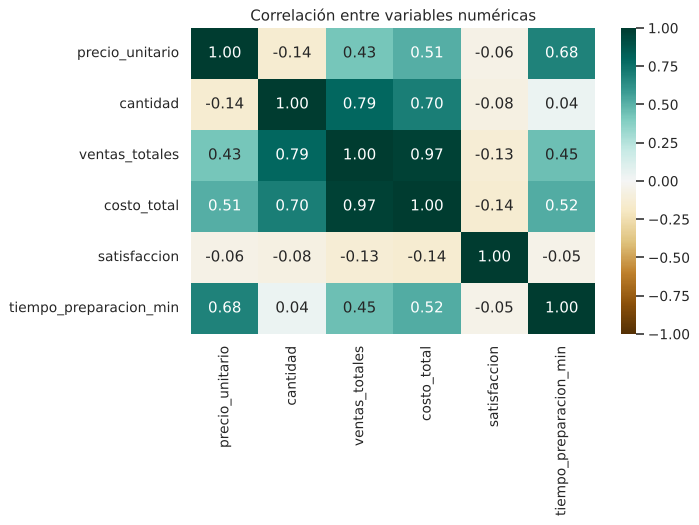

In [22]:
corr = df[numericas].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="BrBG", vmin=-1, vmax=1)
plt.title("Correlación entre variables numéricas")
plt.tight_layout()
plt.show()

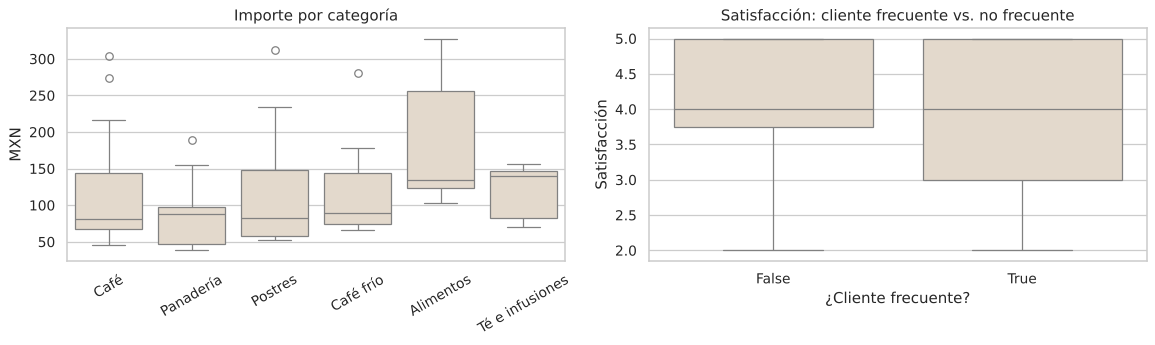

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(x="categoria", y="ventas_totales", data=df, ax=axes[0], color="#E7D9C8")
axes[0].set(title="Importe por categoría", xlabel="", ylabel="MXN")
axes[0].tick_params(axis="x", rotation=30)
sns.boxplot(x="es_cliente_frecuente", y="satisfaccion", data=df, ax=axes[1], color="#E7D9C8")
axes[1].set(title="Satisfacción: cliente frecuente vs. no frecuente", xlabel="¿Cliente frecuente?", ylabel="Satisfacción")
plt.tight_layout()
plt.show()

## 9. Hallazgos y decisiones para la aplicación

### Hallazgos

1. **Datos limpios:** 150 ventas y 17 columnas originales, sin valores faltantes ni duplicados. Solo fue necesario convertir `fecha_venta` a tipo fecha y leer el archivo con `utf-8-sig` por el BOM del encabezado.
2. **Periodo corto:** las ventas van del 01/01/2026 al 29/03/2026 (tres meses), así que no hay suficiente historia para analizar estacionalidad.
3. **Descuentos consistentes:** `ventas_totales` coincide con `precio × cantidad`, excepto en las ventas con descuento, donde se paga en promedio el 91% del importe (9% de descuento). Solo el 13% de las ventas tiene descuento.
4. **Precios por sucursal:** un mismo producto tiene precios distintos según la sucursal, por lo que comparar sucursales solo por precio sería engañoso; conviene compararlas por ingresos y ticket.
5. **Importe sesgado a la derecha:** ticket promedio de $113.18 contra mediana de $90.00. Hay 7 ventas atípicas, que son compras de varias unidades y se conservan.
6. **Lo que impulsa el importe es la cantidad:** la correlación de `ventas_totales` con `cantidad` es 0.79, mayor que con `precio_unitario` (0.43).
7. **Categoría líder:** *Café* concentra el 33.6% de los ingresos; *Té e infusiones* es la de menor participación (7.1%).
8. **Productos:** *Cold brew* es el producto con más ingresos ($1,760.46) y *Matcha latte* el de menos ($553.50).
9. **Sucursales:** *Roma Norte* genera más ingresos por volumen de transacciones, mientras que *Polanco* tiene el ticket promedio más alto ($119.34).
10. **Margen bruto** de 61.2% y satisfacción promedio de 4.08/5.

### Decisiones tomadas en la aplicación (`app.py`)

| Hallazgo del EDA | Decisión en el dashboard |
|---|---|
| `fecha_venta` llega como texto | Se convierte con `pd.to_datetime` al cargar los datos |
| Columnas clave: `ventas_totales`, `producto`, `categoria` | La app valida que existan antes de graficar |
| Varias dimensiones categóricas con pocos valores | Filtros `multiselect` por categoría, producto, sucursal y método de pago |
| Los descuentos explican las diferencias de importe | Casilla para ver solo ventas con descuento |
| Comparar el peso de cada producto y categoría | Gráfico de barras por producto y gráfico de dona por categoría |
| Importe sesgado con valores atípicos | Histograma con boxplot marginal para ver la distribución completa |
| Media y mediana distintas | KPI de ventas totales, número de registros y ticket promedio |
